## **Imports**

In [28]:
import json
import re
import math
import pickle
import random

import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

import torch
import torch.nn as nn
import torch.nn.functional as F


In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


cuda


## **Dataset**

In [3]:
DATA_DIR = "/content/"   # change to wherever the jsonl files are staged on the lab machines

EN_KEY = "en"
DE_KEY = "de"

def load_jsonl(path):
    en_sentences, de_sentences = [], []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            obj = json.loads(line)
            en_sentences.append(obj[EN_KEY])
            de_sentences.append(obj[DE_KEY])
    return de_sentences, en_sentences

train_de, train_en = load_jsonl(f"{DATA_DIR}/train.jsonl")
valid_de, valid_en = load_jsonl(f"{DATA_DIR}/val.jsonl")
test_de,  test_en  = load_jsonl(f"{DATA_DIR}/test.jsonl")

print("Train pairs:", len(train_de))
print("Sample German:", train_de[0])
print("Sample English:", train_en[0])


Train pairs: 29000
Sample German: Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.
Sample English: Two young, White males are outside near many bushes.


## **Preprocessing**

In [4]:
PAD_IDX, SOS_IDX, EOS_IDX, UNK_IDX = 0, 1, 2, 3
MAX_LEN = 32

def tokenize(text):
    text = text.lower().strip()
    # text = re.sub(r"([.,!?\"'])", r" \1 ", text)   # uncomment to split punctuation off as separate tokens
    return text.split()

def text_preprocess_pipeline(text_list, max_len=MAX_LEN):
    processed = []
    for text in text_list:
        tokens = tokenize(text)
        tokens = ["<sos>"] + tokens[: max_len - 2] + ["<eos>"]
        if len(tokens) < max_len:
            tokens += ["<pad>"] * (max_len - len(tokens))
        processed.append(tokens)
    return processed

train_de_tok = text_preprocess_pipeline(train_de)
train_en_tok = text_preprocess_pipeline(train_en)
valid_de_tok = text_preprocess_pipeline(valid_de)
valid_en_tok = text_preprocess_pipeline(valid_en)


In [5]:
def convert_text_to_idx(text_list_tokenized, create_vocab=True, token_to_idx=None):
    if create_vocab:
        token_to_idx = {"<pad>": PAD_IDX, "<sos>": SOS_IDX, "<eos>": EOS_IDX, "<unk>": UNK_IDX}
        idx_to_token = {PAD_IDX: "<pad>", SOS_IDX: "<sos>", EOS_IDX: "<eos>", UNK_IDX: "<unk>"}
        next_idx = 4
    else:
        idx_to_token = {v: k for k, v in token_to_idx.items()}
        next_idx = None

    converted = []
    for tokens in text_list_tokenized:
        ids = []
        for tok in tokens:
            if tok not in token_to_idx:
                if create_vocab:
                    token_to_idx[tok] = next_idx
                    idx_to_token[next_idx] = tok
                    next_idx += 1
                    ids.append(token_to_idx[tok])
                else:
                    ids.append(UNK_IDX)
            else:
                ids.append(token_to_idx[tok])
        converted.append(ids)

    if create_vocab:
        return converted, token_to_idx, idx_to_token
    return converted


train_de_ids, de_token_to_idx, de_idx_to_token = convert_text_to_idx(train_de_tok)
train_en_ids, en_token_to_idx, en_idx_to_token = convert_text_to_idx(train_en_tok)

valid_de_ids = convert_text_to_idx(valid_de_tok, create_vocab=False, token_to_idx=de_token_to_idx)
valid_en_ids = convert_text_to_idx(valid_en_tok, create_vocab=False, token_to_idx=en_token_to_idx)

print("German vocab size:", len(de_token_to_idx))
print("English vocab size:", len(en_token_to_idx))


German vocab size: 24325
English vocab size: 14447


In [6]:
def get_batches(src, tgt, batch_size=64, shuffle=True):
    idx = list(range(len(src)))
    if shuffle:
        random.shuffle(idx)
    for i in range(0, len(idx), batch_size):
        batch_idx = idx[i : i + batch_size]
        src_batch = torch.tensor([src[j] for j in batch_idx], dtype=torch.long).to(device)
        tgt_batch = torch.tensor([tgt[j] for j in batch_idx], dtype=torch.long).to(device)
        yield src_batch, tgt_batch


## **Model Architecture**

In [7]:
d_model = 256
num_heads = 8
num_enc_layers = 3
num_dec_layers = 3
d_ff = 512
dropout = 0.1


In [8]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=MAX_LEN):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.pe = pe.unsqueeze(0)

    def forward(self, x):
        return x + self.pe[:, : x.size(1)].to(x.device)


In [9]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model),
        )

    def forward(self, x):
        return self.net(x)


In [10]:
class EncoderLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.attn = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)
        self.ff = FeedForward(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, src_key_padding_mask=None):
        attn_out, _ = self.attn(x, x, x, key_padding_mask=src_key_padding_mask, need_weights=False)
        x = x + self.dropout(attn_out)
        x = self.norm1(x)

        x = x + self.dropout(self.ff(x))
        x = self.norm2(x)
        return x


In [11]:
class DecoderLayer(nn.Module):
    def __init__(self):
        super().__init__()
        self.self_attn = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)
        self.cross_attn = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)
        self.ff = FeedForward(d_model, d_ff)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, enc_out, tgt_causal_mask=None, tgt_key_padding_mask=None, src_key_padding_mask=None):
        self_out, _ = self.self_attn(
            x, x, x,
            attn_mask=tgt_causal_mask,
            key_padding_mask=tgt_key_padding_mask,
            need_weights=False,
        )
        x = x + self.dropout(self_out)
        x = self.norm1(x)

        cross_out, _ = self.cross_attn(
            x, enc_out, enc_out,
            key_padding_mask=src_key_padding_mask,
            need_weights=False,
        )
        x = x + self.dropout(cross_out)
        x = self.norm2(x)

        x = x + self.dropout(self.ff(x))
        x = self.norm3(x)
        return x


In [12]:
def make_key_padding_mask(x):
    # x: (B, L) token ids -> (B, L) bool, True = <pad> (ignore this position as a key)
    return x == PAD_IDX

def generate_causal_mask(T, device):
    # (T, T) bool, True = future position, not allowed to attend
    return torch.triu(torch.ones(T, T, dtype=torch.bool, device=device), diagonal=1)


In [13]:
class Transformer(nn.Module):
    def __init__(self, src_vocab, tgt_vocab):
        super().__init__()
        self.src_emb = nn.Embedding(src_vocab, d_model, padding_idx=PAD_IDX)
        self.tgt_emb = nn.Embedding(tgt_vocab, d_model, padding_idx=PAD_IDX)
        self.pos = PositionalEncoding(d_model)

        self.encoder = nn.ModuleList([EncoderLayer() for _ in range(num_enc_layers)])
        self.decoder = nn.ModuleList([DecoderLayer() for _ in range(num_dec_layers)])

        self.fc = nn.Linear(d_model, tgt_vocab)

    def encode(self, src, src_key_padding_mask):
        x = self.pos(self.src_emb(src))
        for layer in self.encoder:
            x = layer(x, src_key_padding_mask)
        return x

    def decode(self, tgt, enc_out, tgt_causal_mask, tgt_key_padding_mask, src_key_padding_mask):
        x = self.pos(self.tgt_emb(tgt))
        for layer in self.decoder:
            x = layer(x, enc_out, tgt_causal_mask, tgt_key_padding_mask, src_key_padding_mask)
        return self.fc(x)

    def forward(self, src, tgt):
        src_kpm = make_key_padding_mask(src)
        tgt_kpm = make_key_padding_mask(tgt)
        causal_mask = generate_causal_mask(tgt.size(1), tgt.device)

        enc_out = self.encode(src, src_kpm)
        out = self.decode(tgt, enc_out, causal_mask, tgt_kpm, src_kpm)
        return out


## **Training**

In [18]:
model = Transformer(len(de_token_to_idx), len(en_token_to_idx)).to(device)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 15
BATCH_SIZE = 64


In [19]:
def evaluate_loss(model, src_ids, tgt_ids, batch_size=BATCH_SIZE):
    model.eval()
    total_loss = 0.0
    n_batches = 0
    with torch.no_grad():
        for src, tgt in get_batches(src_ids, tgt_ids, batch_size=batch_size, shuffle=False):
            output = model(src, tgt[:, :-1])
            loss = criterion(
                output.reshape(-1, output.size(-1)),
                tgt[:, 1:].reshape(-1),
            )
            total_loss += loss.item()
            n_batches += 1
    return total_loss / n_batches


In [20]:
train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    n_batches = 0

    for src, tgt in get_batches(train_de_ids, train_en_ids, batch_size=BATCH_SIZE):
        optimizer.zero_grad()

        output = model(src, tgt[:, :-1])   # decoder input: everything but last token

        loss = criterion(
            output.reshape(-1, output.size(-1)),
            tgt[:, 1:].reshape(-1),        # decoder target: everything but <sos>
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        n_batches += 1

    avg_train_loss = total_loss / n_batches
    avg_val_loss = evaluate_loss(model, valid_de_ids, valid_en_ids)

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    print(f"Epoch {epoch+1}/{EPOCHS} - train_loss: {avg_train_loss:.4f} - val_loss: {avg_val_loss:.4f}")


Epoch 1/15 - train_loss: 5.4369 - val_loss: 4.3283
Epoch 2/15 - train_loss: 4.0533 - val_loss: 3.7483
Epoch 3/15 - train_loss: 3.5857 - val_loss: 3.4195
Epoch 4/15 - train_loss: 3.2762 - val_loss: 3.2132
Epoch 5/15 - train_loss: 3.0375 - val_loss: 3.0496
Epoch 6/15 - train_loss: 2.8379 - val_loss: 2.9259
Epoch 7/15 - train_loss: 2.6688 - val_loss: 2.8409
Epoch 8/15 - train_loss: 2.5179 - val_loss: 2.7679
Epoch 9/15 - train_loss: 2.3796 - val_loss: 2.6981
Epoch 10/15 - train_loss: 2.2546 - val_loss: 2.6556
Epoch 11/15 - train_loss: 2.1368 - val_loss: 2.6158
Epoch 12/15 - train_loss: 2.0263 - val_loss: 2.5895
Epoch 13/15 - train_loss: 1.9235 - val_loss: 2.5685
Epoch 14/15 - train_loss: 1.8211 - val_loss: 2.5586
Epoch 15/15 - train_loss: 1.7266 - val_loss: 2.5548


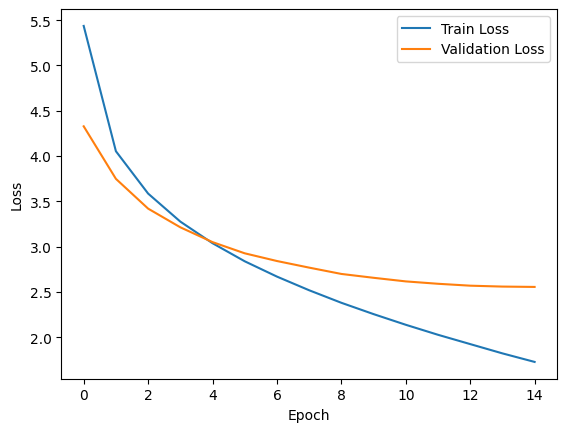

In [21]:
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [22]:
torch.save(model.state_dict(), "transformer_translation_model.pth")

with open("de_vocab.pkl", "wb") as f:
    pickle.dump(de_token_to_idx, f)
with open("en_vocab.pkl", "wb") as f:
    pickle.dump(en_token_to_idx, f)


## **Beam Search**

In [23]:
def beam_search_decode(model, src_ids, beam_width=3, max_len=MAX_LEN, alpha=0.7):
    """
    Returns a list of (token_ids, score) tuples, length beam_width, sorted best-first
    by length-normalized score. The best sequence is the first element:
        all_seqs = beam_search_decode(...)
        best_ids, best_score = all_seqs[0]
    """
    model.eval()
    with torch.no_grad():
        src = torch.tensor(src_ids, dtype=torch.long, device=device).unsqueeze(0)   # (1, S)
        src_kpm = make_key_padding_mask(src)                                        # (1, S)
        enc_out = model.encode(src, src_kpm)                                        # (1, S, d_model)

        beams = [([SOS_IDX], 0.0)]
        completed = []

        for _ in range(max_len - 1):
            if not beams:
                break

            batch_size = len(beams)
            cur_len = len(beams[0][0])

            tgt_batch = torch.tensor([b[0] for b in beams], dtype=torch.long, device=device)   # (n_live, cur_len)
            enc_out_batch = enc_out.expand(batch_size, -1, -1)
            src_kpm_batch = src_kpm.expand(batch_size, -1)
            causal_mask = generate_causal_mask(cur_len, device)

            logits = model.decode(tgt_batch, enc_out_batch, causal_mask, None, src_kpm_batch)  # (n_live, cur_len, V)
            log_probs = F.log_softmax(logits[:, -1, :], dim=-1)                                # (n_live, V)

            candidates = []
            for i, (seq, score) in enumerate(beams):
                topk_logp, topk_idx = log_probs[i].topk(beam_width)
                for logp, tok in zip(topk_logp.tolist(), topk_idx.tolist()):
                    candidates.append((seq + [tok], score + logp))

            candidates.sort(key=lambda x: x[1], reverse=True)

            new_beams = []
            for seq, score in candidates:
                if seq[-1] == EOS_IDX:
                    completed.append((seq, score))
                else:
                    new_beams.append((seq, score))
                if len(new_beams) == beam_width:
                    break

            beams = new_beams

        completed.extend(beams)

        def length_normalized(item):
            seq, score = item
            return score / (len(seq) ** alpha)

        completed.sort(key=length_normalized, reverse=True)
        return completed[:beam_width]


In [24]:
def ids_to_sentence(ids, idx_to_token):
    words = []
    for i in ids:
        tok = idx_to_token.get(i, "<unk>")
        if tok == "<eos>":
            break
        if tok not in ("<pad>", "<sos>"):
            words.append(tok)
    return " ".join(words)


sample_src_ids = train_de_ids[2]
all_seqs = beam_search_decode(model, sample_src_ids, beam_width=3)

print("Source (de):   ", " ".join(t for t in train_de_tok[2] if t != "<pad>"))
print("Reference (en):", " ".join(t for t in train_en_tok[2] if t != "<pad>"))
for rank, (ids, score) in enumerate(all_seqs, 1):
    print(f"Beam #{rank} (score={score:.3f}): {ids_to_sentence(ids, en_idx_to_token)}")


Source (de):    <sos> ein kleines mädchen klettert in ein spielhaus aus holz. <eos>
Reference (en): <sos> a little girl climbing into a wooden playhouse. <eos>
Beam #1 (score=-6.071): a little girl is climbing into a pool of wood.
Beam #2 (score=-6.074): a little girl is climbing into a wooden building.
Beam #3 (score=-6.440): a little girl is climbing into a wooden house


## **BLEU Score**

In [25]:
test_de_tok = text_preprocess_pipeline(test_de)
test_en_tok = text_preprocess_pipeline(test_en)

test_de_ids = convert_text_to_idx(test_de_tok, create_vocab=False, token_to_idx=de_token_to_idx)
test_en_ids = convert_text_to_idx(test_en_tok, create_vocab=False, token_to_idx=en_token_to_idx)

print("Test pairs:", len(test_de_ids))


Test pairs: 1000


In [26]:
def get_ngrams(tokens, n):
    return [tuple(tokens[i : i + n]) for i in range(len(tokens) - n + 1)]

def corpus_bleu_score(references, hypotheses, max_n=4):
    # references / hypotheses: list of token lists, one entry per sentence
    weights = [0.25] * max_n
    clipped_counts = [0] * max_n
    total_counts = [0] * max_n
    ref_len_total = 0
    hyp_len_total = 0

    for ref, hyp in zip(references, hypotheses):
        ref_len_total += len(ref)
        hyp_len_total += len(hyp)
        for n in range(1, max_n + 1):
            hyp_ngrams = Counter(get_ngrams(hyp, n))
            ref_ngrams = Counter(get_ngrams(ref, n))
            clipped = sum(min(c, ref_ngrams[g]) for g, c in hyp_ngrams.items())
            clipped_counts[n - 1] += clipped
            total_counts[n - 1] += sum(hyp_ngrams.values())

    if hyp_len_total == 0:
        return 0.0

    # +1 smoothing avoids a single zero n-gram-precision collapsing the whole score
    precisions = [(clipped_counts[n] + 1) / (total_counts[n] + 1) for n in range(max_n)]

    brevity_penalty = 1.0 if hyp_len_total > ref_len_total else math.exp(1 - ref_len_total / hyp_len_total)
    log_precision_sum = sum(w * math.log(p) for w, p in zip(weights, precisions))

    return brevity_penalty * math.exp(log_precision_sum)


In [29]:
EVAL_SIZE = 100   # tune based on timing on your actual lab GPUs

references = []
hypotheses = []

n_eval = min(EVAL_SIZE, len(test_de_ids))
for i in range(n_eval):
    ref_words = ids_to_sentence(test_en_ids[i], en_idx_to_token).split()

    all_seqs = beam_search_decode(model, test_de_ids[i], beam_width=3)
    best_ids, _ = all_seqs[0]
    hyp_words = ids_to_sentence(best_ids, en_idx_to_token).split()

    references.append(ref_words)
    hypotheses.append(hyp_words)

    if (i + 1) % 50 == 0:
        print(f"Decoded {i + 1}/{n_eval}")

bleu = corpus_bleu_score(references, hypotheses)
print(f"\nTest BLEU (beam width=3, n={n_eval} sentences): {bleu * 100:.2f}")


Decoded 50/100
Decoded 100/100

Test BLEU (beam width=3, n=100 sentences): 26.52


## **Inference**

In [30]:
NUM_INFERENCE_SENTENCES = 5
inference_indices = list(range(NUM_INFERENCE_SENTENCES))  # first 5 test sentences

for idx in inference_indices:
    src_ids = test_de_ids[idx]
    all_seqs = beam_search_decode(model, src_ids, beam_width=3)

    print(f"\n--- Example {idx + 1} ---")
    print("Source (de):   ", " ".join(t for t in test_de_tok[idx] if t != "<pad>"))
    print("Reference (en):", " ".join(t for t in test_en_tok[idx] if t != "<pad>"))
    for rank, (ids, score) in enumerate(all_seqs, 1):
        print(f"Beam #{rank} (score={score:.3f}): {ids_to_sentence(ids, en_idx_to_token)}")



--- Example 1 ---
Source (de):    <sos> ein mann mit einem orangefarbenen hut, der etwas anstarrt. <eos>
Reference (en): <sos> a man in an orange hat starring at something. <eos>
Beam #1 (score=-6.225): a man with an orange hat is cleaning something.
Beam #2 (score=-6.303): a man wearing an orange hat is cleaning something.
Beam #3 (score=-8.019): a man with an orange hat is cleaning something

--- Example 2 ---
Source (de):    <sos> ein boston terrier läuft über saftig-grünes gras vor einem weißen zaun. <eos>
Reference (en): <sos> a boston terrier is running on lush green grass in front of a white fence. <eos>
Beam #1 (score=-6.311): a musician is walking across the grass in front of a white fence.
Beam #2 (score=-6.507): a musician is running across the grass in front of a white fence.
Beam #3 (score=-6.663): a teacher is running across the grass in front of a white fence.

--- Example 3 ---
Source (de):    <sos> ein mädchen in einem karateanzug bricht ein brett mit einem tritt. <eo